# Solar PV Panel Defect Detection Using Multimodal Fusion Architecture

## Module-1: Defining the Problem Statement

* Photovoltaic (PV) solar panels are susceptible to various kind of wear and tear such as: Thermal Fatigue, Micro-Cracking during fabrication, transportation, installatiion. 
* These wear and tear directly results in performance degradation of the solar panels.
* To detect those degraded panels the PV panels are imaged using Electroluminescence (EL) imaging techniques and respectve electrical sensor readings are noted.
* The EL imaging is subjective to low radiometric contrast, sensor speckle noise, and visual artifacts, especially in polycrystalline silicon wafers the grain boundaries and micro cracks sometimes and look identical and hard to detect.
* Similarly the sensor reading alone is not sufficient enough to accurately detect the degraded panels as it may sometimes contains irregular reading and suffer form various noises such as sensor acquisition noise, thermal noise, etc.
* We are addressing this problem by using a multimodal fusion network to consider both the EL images and the sensor readings for classifying the PV cells according to their defect percentage.


## Module-2: Undersatanding the Dataset

* Using the ELPV dataset

       filename  defect_prob wafer_type
0  cell0000.png          1.0       mono
1  cell0001.png          1.0       mono
2  cell0002.png          1.0       mono
3  cell0003.png          0.0       mono
4  cell0004.png          1.0       mono


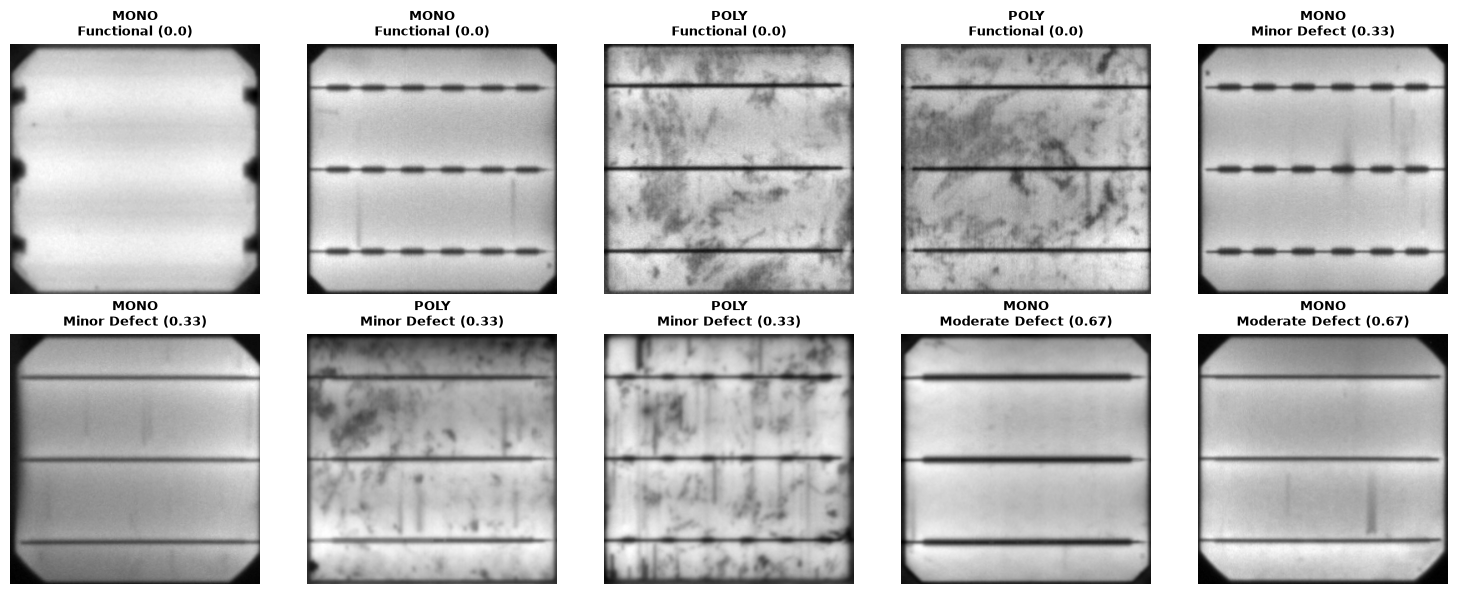

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import os
from PIL import Image
from pathlib import Path

SRC_DIR = Path(__file__).resolve().parent if "__file__" in locals() else Path.cwd()
PROJECT_ROOT = SRC_DIR.parent if SRC_DIR.name in ["src", "notebooks"] else SRC_DIR

LABELS_PATH = PROJECT_ROOT / "data" / "labels.csv"
IMAGES_DIR = PROJECT_ROOT / "data" / "raw" / "elpv_images"

pv_labels = pd.read_csv(LABELS_PATH)
print(pv_labels.head())

# Ensuring columns are stripped of accidental leading/trailing spaces
pv_labels.columns = pv_labels.columns.str.strip()

pv_labels["full_path"] = [IMAGES_DIR / str(fname).strip() for fname in pv_labels["filename"]]

# Stratified Sampling 
sampled_groups = []
for _, group in pv_labels.groupby(["defect_prob", "wafer_type"]):
    # Sample up to 2 items per group safely
    n_samples = min(len(group), 2)
    sampled_groups.append(group.sample(n=n_samples, random_state=42))

# Combining back into a single dataframe and taking the first 10 data
samples = pd.concat(sampled_groups).head(10).reset_index(drop=True)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()

defect_descriptions = {
    0.0: "Functional (0.0)",
    0.333: "Minor Defect (0.33)",
    0.667: "Moderate Defect (0.67)",
    1.0: "Severe / Broken (1.0)"
}

for i, (_, row) in enumerate(samples.iterrows()):
    img_path: Path = row["full_path"]
    
    if img_path.is_file():
        with Image.open(img_path) as img:
            axes[i].imshow(img.convert("L"), cmap="gray")
    else:
        axes[i].text(0.5, 0.5, f"Missing:\n{img_path.name}", 
                     ha="center", va="center", color="red", fontsize=8)

    prob_val = float(row["defect_prob"])
    prob_key = round(prob_val, 3)
    
    label_desc = defect_descriptions.get(prob_key, f"Prob: {prob_val}")
    wafer_str = str(row['wafer_type']).strip().upper()
    
    axes[i].set_title(f"{wafer_str}\n{label_desc}", fontsize=9, fontweight="bold")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

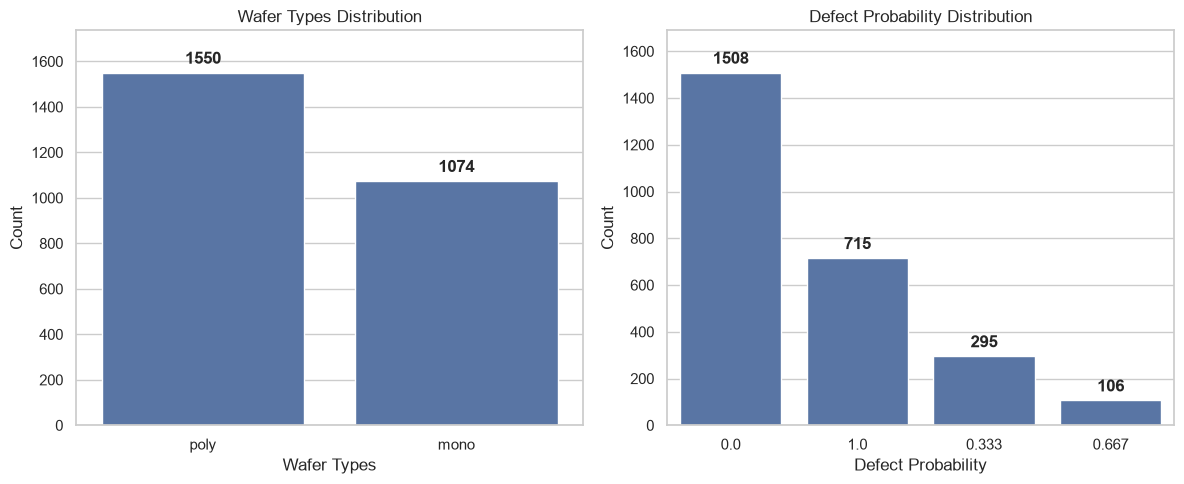

In [2]:
sns.set_theme(style='whitegrid')
plt.figure(figsize=(12,5))

def plotDistributions(dataset,feature,title,i):
    plt.subplot(1,2,i)
    sns.countplot(data=dataset,
              x=feature,
              order=dataset[feature].value_counts().index)
    plt.title(f"{title} Distribution")
    plt.xlabel(title)
    plt.ylabel("Count")

    for c in plt.gca().containers:
        plt.gca().bar_label(c, padding=4, fontweight="bold")
    plt.margins(y=0.12)

plotDistributions(pv_labels,'wafer_type','Wafer Types',1)
plotDistributions(pv_labels,'defect_prob','Defect Probability',2)

plt.tight_layout()
plt.show()

* From the image we can infer that the dataset is skewed, the defect probability 0.333 and 0.667 are under represented in the dataset. 
* And defect probability 0.0 has more double samples than of the second most represented defect probability 1.0.
* To increase the variations and to make our model more robust to bias, we are generating a synthetic sensor readings from the available defect probability of the PV cells.

In [12]:
TELEMETRY_PATH = PROJECT_ROOT / "data" / "paired_telemetry.csv"
pv_telemetry = pd.read_csv(TELEMETRY_PATH)
print(pv_telemetry.head(10))
print('\n',pv_telemetry.groupby('defect_prob').describe().T.round(2))
print(pv_telemetry.info())

       filename  defect_prob wafer_type     voc     isc      rsh   temp
0  cell0000.png          1.0       mono  0.5324  7.6117    77.59  41.68
1  cell0001.png          1.0       mono  0.5293  7.5755    75.71  38.81
2  cell0002.png          1.0       mono  0.5331  7.6400    69.11  41.65
3  cell0003.png          0.0       mono  0.6173  8.8699  1805.48  24.73
4  cell0004.png          1.0       mono  0.5289  7.5874    71.48  39.05
5  cell0005.png          1.0       mono  0.5289  7.5863    66.66  39.75
6  cell0006.png          1.0       mono  0.5376  7.6085    69.82  39.06
7  cell0007.png          1.0       mono  0.5337  7.6132    68.31  39.80
8  cell0008.png          0.0       mono  0.6077  8.8556  1806.08  24.00
9  cell0009.png          1.0       mono  0.5326  7.6089    70.19  39.32

 defect_prob    0.000   0.333   0.667   1.000
voc  count   1508.00  295.00  106.00  715.00
     mean       0.61    0.58    0.56    0.53
     std        0.00    0.00    0.00    0.00
     min        0.60    0.

* Also performing data augmentation to increase the size of the training dataset before feeding to the model.

| Defect Class | Severity Meaning | Total in ELPV | Train Split (80%) | After $D_8$ Augmentation |
| --- | --- | --- | --- | --- |
| **0.0** | Functional Wafer | 1,508 (57.5%) | ~1,206 | 9,648 |
| **0.33** | Minor Defect | 295 (11.2%) | ~236 | 1,888 |
| **0.67** | Moderate Defect | 106 (4.0%) | ~85 | 680 |
| **1.0** | Severe Defect / Broken Wafer | 715 (27.3%) | ~572 | 4,576 |
